# 03. Feature Engineering

Xử lý missing values, chuẩn hóa phân loại, tạo feature mới.

Quy trình:
1. Chia train/test trước khi xử lý (tránh rò rỉ dữ liệu)
2. Thêm missing indicator và điền missing values
3. Chuẩn hóa giá trị phân loại (gộp trùng ý nghĩa, chuyển cột số phi định lượng)
4. Tạo feature mới từ các biến hiện có
5. One-hot encode biến phân loại
6. Lưu dữ liệu đã xử lý vào `data/processed/`

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

df = pd.read_excel('../data/raw/churn_prediction.xlsx')
df.shape

(5630, 20)

In [57]:
# Thống kê các cột có missing values
list_null = df.columns[df.isnull().any()].tolist()
missing_df = pd.DataFrame({
    'Missing Values': df[list_null].isnull().sum(),
    'Percentage (%)': df[list_null].isnull().mean() * 100
}).sort_values('Missing Values', ascending=False)
missing_df

,Missing Values,Percentage (%)
DaySinceLastOrder,307,5.452931
OrderAmountHikeFromlastYear,265,4.706927
Tenure,264,4.689165
OrderCount,258,4.582593
CouponUsed,256,4.547069
HourSpendOnApp,255,4.529307
WarehouseToHome,251,4.458259


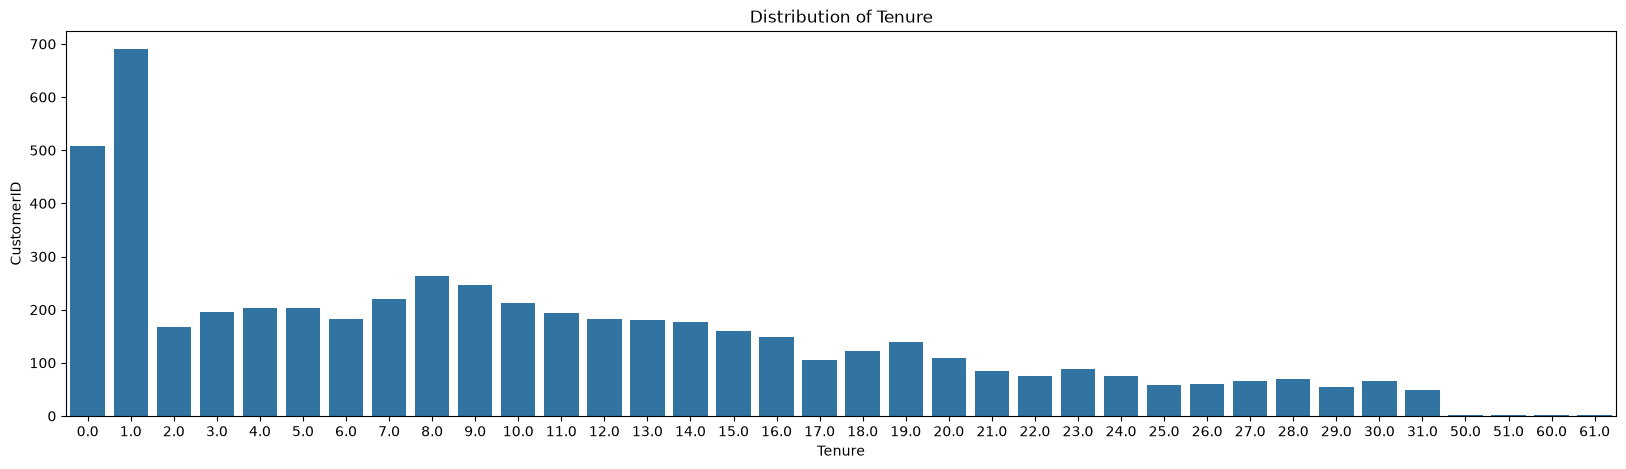

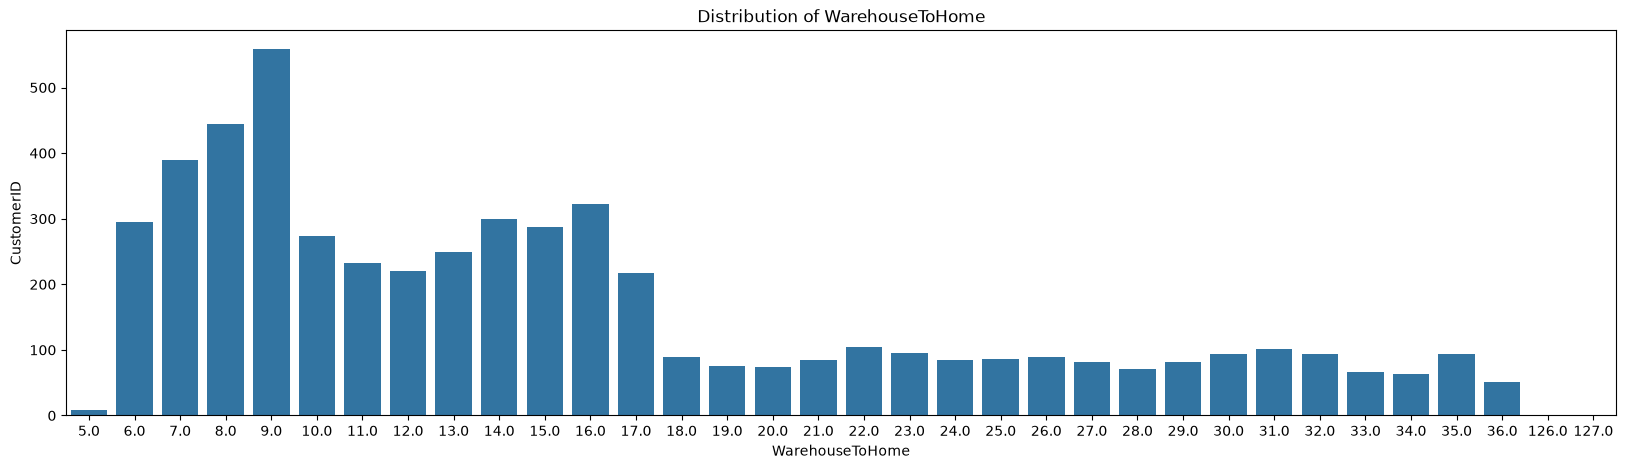

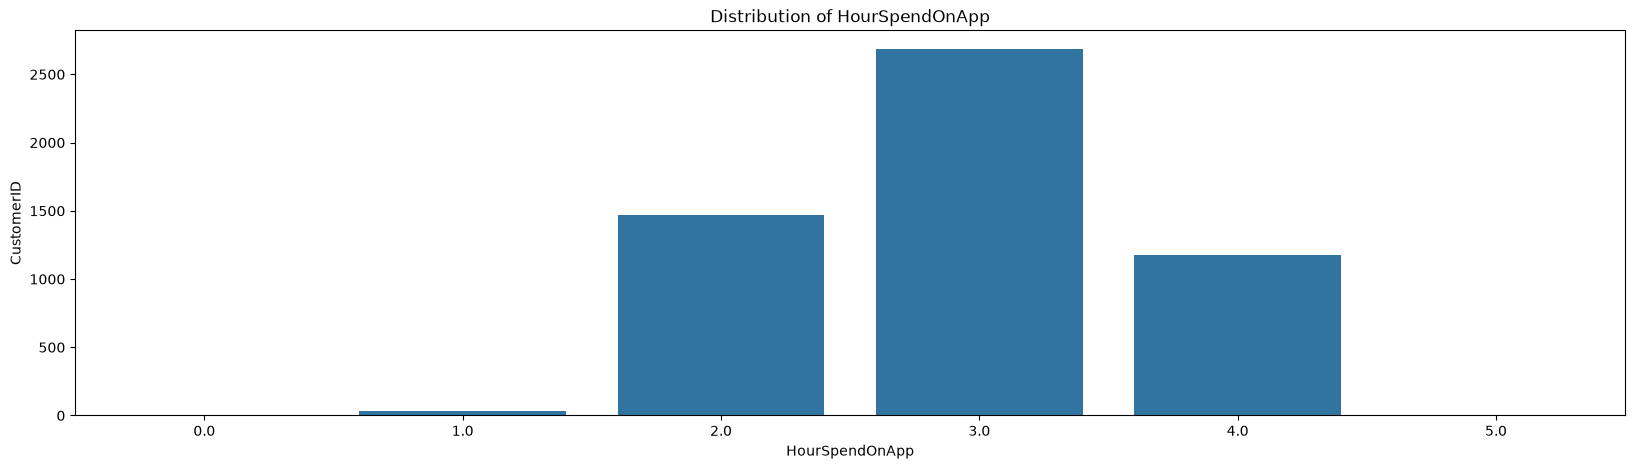

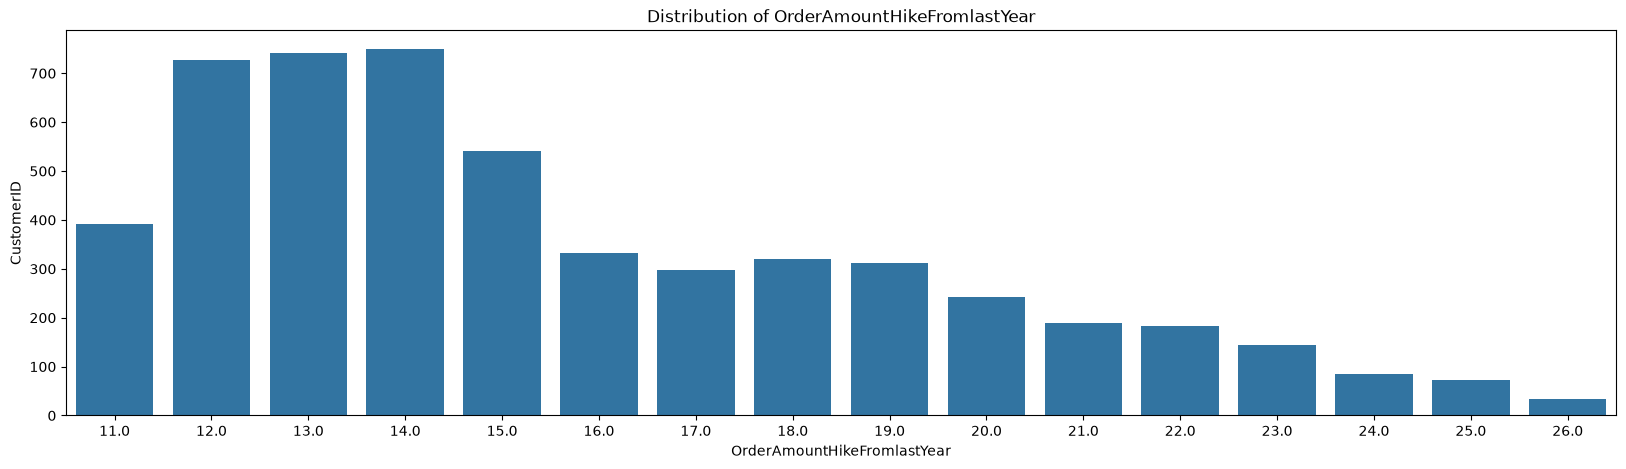

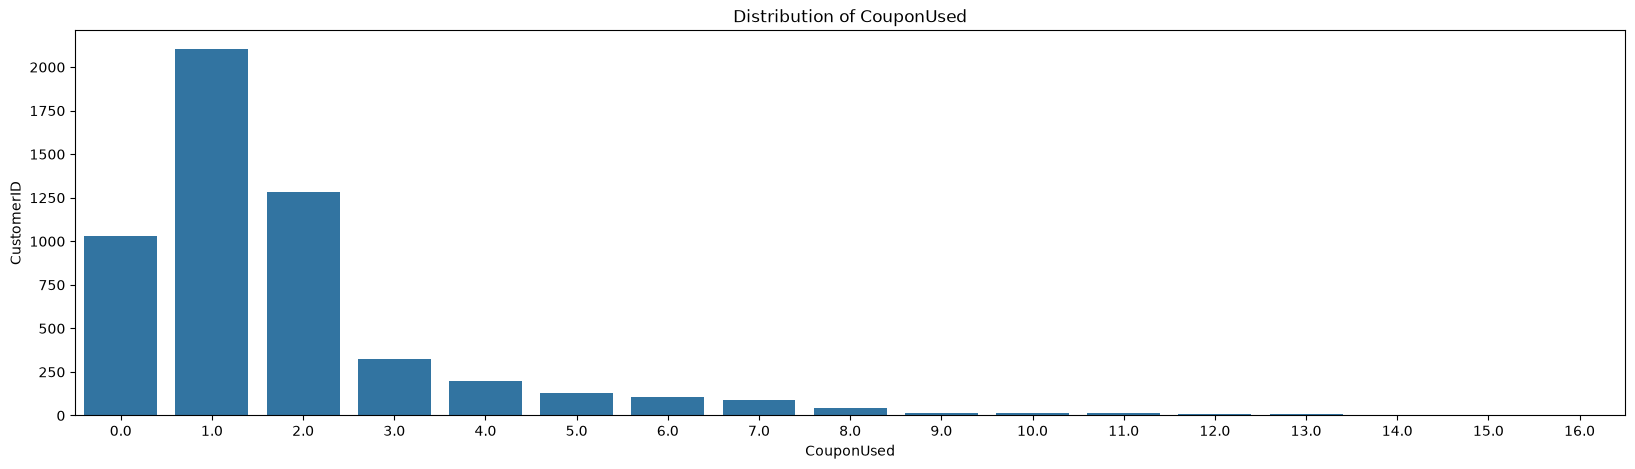

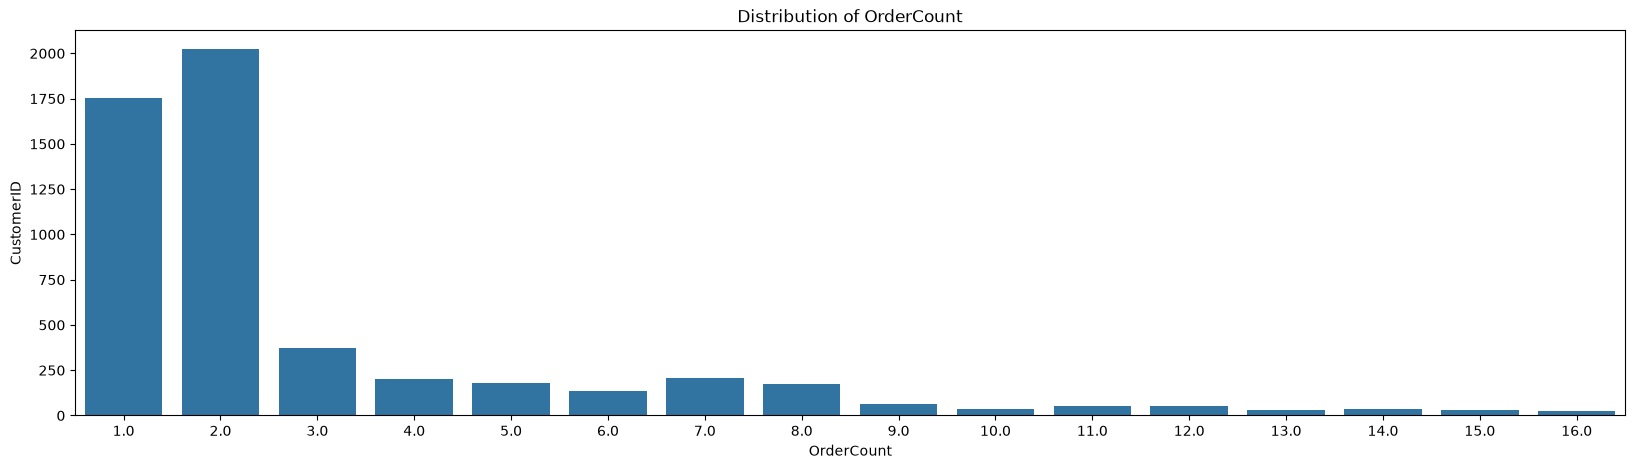

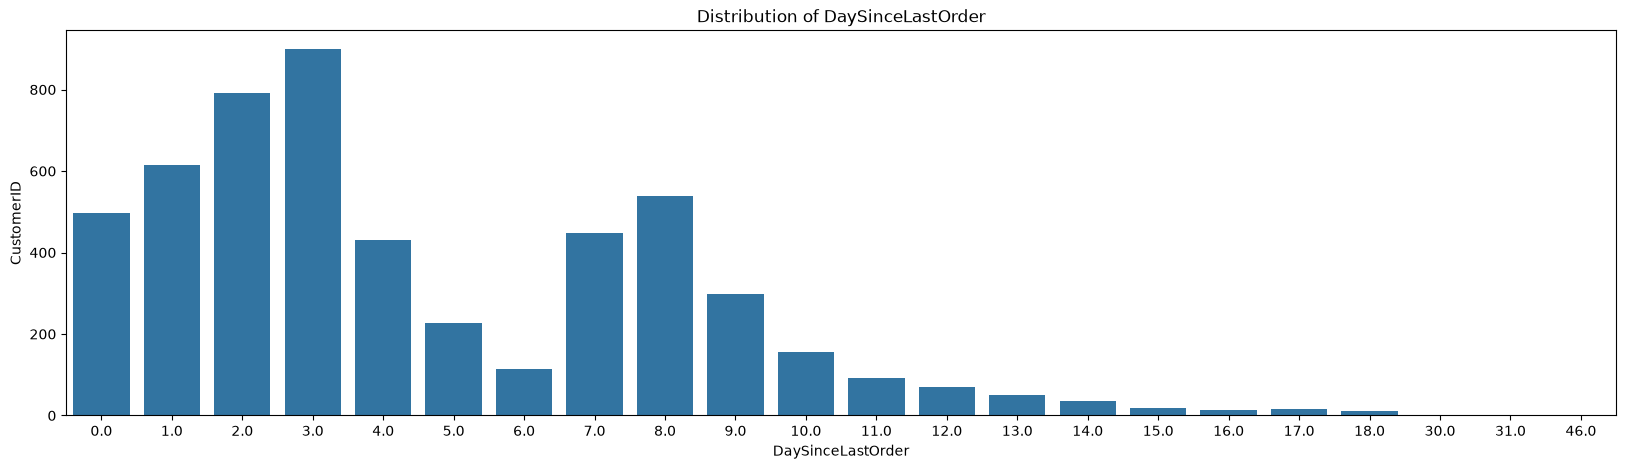

In [58]:
# Xem phân phối giá trị hiện có của từng cột có missing values
for col in list_null:
    fig, ax = plt.subplots(figsize=(20, 5))
    plot_df = df.groupby(col)[['CustomerID']].count().reset_index()
    sns.barplot(data=plot_df, x=plot_df[col], y=plot_df['CustomerID'], ax=ax)
    ax.set_title(f'Distribution of {col}')
    plt.show()

## Bước 1: Chia train/test trước khi xử lý missing values

Chia dữ liệu trước, sau đó mới tính median trên tập train để tránh rò rỉ thông tin từ tập test.

In [59]:
# Tách feature và target
X = df.drop(columns=['CustomerID', 'Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Train churn rate:', round(y_train.mean(), 4))
print('Test churn rate:', round(y_test.mean(), 4))

Train: (4504, 18) | Test: (1126, 18)
Train churn rate: 0.1683
Test churn rate: 0.1687


## Bước 2: Thêm missing indicator và điền missing values

**Phân tích:** bản thân việc thiếu dữ liệu là tín hiệu mạnh về Churn — nhóm thiếu `Tenure` có churn rate 30.7% (gấp đôi trung bình 16.8%), thiếu `WarehouseToHome` 33.5%, trong khi nhóm thiếu `CouponUsed` chỉ 3.1%. Đặc biệt các cột không bao giờ thiếu cùng lúc (mỗi dòng thiếu tối đa 1 cột), nên 7 indicator này là 7 tín hiệu độc lập.

**Chiến lược điền:**
- Thêm cột `{col}_missing` (0/1) cho mỗi cột thiếu dữ liệu, giữ lại thông tin về việc thiếu.
- Điền bằng **median của tập train**: 6/7 cột có phân phối lệch (skew 0.7–2.6) nên median robust hơn mean.
- **Không điền 0** cho `CouponUsed`/`OrderCount`/`OrderAmountHikeFromlastYear`: nhóm thiếu các cột này có churn rate rất thấp (3–7%) → là khách trung thành, điền 0 sẽ gán nhầm vào nhóm ít tương tác.
- `HourSpendOnApp` gần đối xứng (skew -0.03, mean ≈ median) → mean hoặc median đều ổn.
- Lưu ý: nếu chỉ dùng LightGBM/XGBoost thì có thể để nguyên NaN (xử lý native), nhưng indicator vẫn hữu ích cho baseline Logistic Regression.

In [60]:
# Copy để tranh ghi vao DataFrame goc
X_train = X_train.copy()
X_test = X_test.copy()

# 1. Them missing indicator: viec thieu du lieu tu no la tin hieu manh ve Churn
for col in list_null:
    X_train[f'{col}_missing'] = X_train[col].isnull().astype(int)
    X_test[f'{col}_missing'] = X_test[col].isnull().astype(int)

# 2. Điền missing bằng median của tập TRAIN (áp dụng cho cả train và test)
cols_with_na = X_train.columns[X_train.isnull().any()].tolist()
medians = X_train[cols_with_na].median()
X_train[cols_with_na] = X_train[cols_with_na].fillna(medians)
X_test[cols_with_na] = X_test[cols_with_na].fillna(medians)

# Kiểm tra lại missing values sau khi điền
print('Missing in train:', X_train.isnull().sum().sum())
print('Missing in test:', X_test.isnull().sum().sum())
print('So feature:', X_train.shape[1])

Missing in train: 0
Missing in test: 0
So feature: 25


## Bước 3: Chuẩn hóa giá trị phân loại

**Gộp các giá trị trùng ý nghĩa** (dữ liệu gốc nhập không thống nhất):
- `PreferredLoginDevice`: 'Phone' → 'Mobile Phone' (1,231 dòng)
- `PreferredPaymentMode`: 'COD' → 'Cash on Delivery' (365 dòng), 'CC' → 'Credit Card' (273 dòng)
- `PreferedOrderCat`: 'Mobile' → 'Mobile Phone' (809 dòng) — trùng ý nghĩa với 'Mobile Phone'

**Chuyển cột số nhưng ý nghĩa là nhãn phân loại** sang `category`:
- `CityTier` (1/2/3): phân khúc thành phố — nhãn, khoảng cách giữa các tier không có ý nghĩa

Giữ nguyên dạng số:
- `SatisfactionScore` (1–5): thang điểm thứ tự (ordinal) — thứ tự và khoảng cách giữa các mức có ý nghĩa
- `Complain` (0/1): cờ nhị phân — đã là dạng số chuẩn 0/1
- Các cột đếm thực sự: `NumberOfDeviceRegistered`, `NumberOfAddress`, `OrderCount`, `CouponUsed`

In [61]:
# 1. Gop cac gia tri trung y nghia
login_device_map = {'Phone': 'Mobile Phone'}
payment_mode_map = {
    'COD': 'Cash on Delivery',
    'CC': 'Credit Card'
}
order_cat_map = {'Mobile': 'Mobile Phone'}

for col, mapping in [
    ('PreferredLoginDevice', login_device_map),
    ('PreferredPaymentMode', payment_mode_map),
    ('PreferedOrderCat', order_cat_map)
]:
    X_train[col] = X_train[col].replace(mapping)
    X_test[col] = X_test[col].replace(mapping)

# 2. Cot so nhung y nghia la nhan phan loai
    X_train['CityTier'] = X_train['CityTier'].astype('object')
    X_test['CityTier'] = X_test['CityTier'].astype('object')

# Kiem tra ket qua
print('PreferredLoginDevice:', sorted(X_train['PreferredLoginDevice'].unique()))
print('PreferredPaymentMode:', sorted(X_train['PreferredPaymentMode'].unique()))
print('PreferedOrderCat:', sorted(X_train['PreferedOrderCat'].unique()))
print('Chuyen thanh object: CityTier')

PreferredLoginDevice: ['Computer', 'Mobile Phone']
PreferredPaymentMode: ['Cash on Delivery', 'Credit Card', 'Debit Card', 'E wallet', 'UPI']
PreferedOrderCat: ['Fashion', 'Grocery', 'Laptop & Accessory', 'Mobile Phone', 'Others']
Chuyen thanh object: CityTier


## Bước 4: Tạo feature mới

Dựa trên kết quả EDA (Tenure, Complain, DaySinceLastOrder, CouponUsed, HourSpendOnApp là các biến liên quan đến churn), tạo thêm:
- `CouponPerOrder`: số coupon trung bình mỗi đơn hàng
- `IsRecentBuyer`: khách hàng có mua hàng gần đây (<= 7 ngày)
- `AppEngagement`: mức độ tương tác trên app (giờ trên app × số đơn hàng)
- `TenureGroup`: nhóm thời gian gắn bó (New / Mid / Senior)

In [62]:
def add_features(X):
    X = X.copy()
    # Số coupon trung bình mỗi đơn hàng
    X['CouponPerOrder'] = X['CouponUsed'] / X['OrderCount'].replace(0, np.nan)
    X['CouponPerOrder'] = X['CouponPerOrder'].fillna(0)
    # Khách hàng có mua hàng gần đây (trong vòng 7 ngày)
    X['IsRecentBuyer'] = (X['DaySinceLastOrder'] <= 7).astype(int)
    # Chỉ số tương tác trên app
    X['AppEngagement'] = X['HourSpendOnApp'] * X['OrderCount']
    # Nhóm thời gian gắn bó
    X['TenureGroup'] = pd.cut(
        X['Tenure'], bins=[-np.inf, 12, 36, np.inf],
        labels=['New', 'Mid', 'Senior']
    ).astype(str)
    return X

X_train = add_features(X_train)
X_test = add_features(X_test)
X_train[['CouponPerOrder', 'IsRecentBuyer', 'AppEngagement', 'TenureGroup']].head()

,CouponPerOrder,IsRecentBuyer,AppEngagement,TenureGroup
1783,1.000000,0,6.0,New
2142,0.500000,1,8.0,New
1708,0.000000,1,3.0,Mid
2275,1.000000,1,3.0,New
5582,0.428571,1,21.0,Mid


In [63]:
# Kiểm tra nhanh churn rate theo các feature mới
train_check = X_train.copy()
train_check['Churn'] = y_train.values

print('Churn rate theo IsRecentBuyer:')
print(train_check.groupby('IsRecentBuyer')['Churn'].mean().round(4))
print('\nChurn rate theo TenureGroup:')
print(train_check.groupby('TenureGroup')['Churn'].mean().round(4))

Churn rate theo IsRecentBuyer:
IsRecentBuyer
0    0.0958
1    0.1899
Name: Churn, dtype: float64

Churn rate theo TenureGroup:
TenureGroup
Mid       0.0518
New       0.2293
Senior    0.0000
Name: Churn, dtype: float64


## Bước 5: Encode biến phân loại

One-hot encode các biến phân loại (bao gồm cột `category` mới chuyển đổi), dùng `drop_first=True` để giảm đa cộng tuyến. Căn chỉnh cột giữa train và test để đảm bảo cùng không gian feature.

In [64]:
# Lưu ý: cột 'PreferedOrderCat' bị thiếu chính tả trong dữ liệu gốc
cat_cols = X_train.select_dtypes(include=['object', 'str', 'category']).columns.tolist()
print('Categorical columns:', cat_cols)

X_train_enc = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test_enc = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)

# Căn chỉnh cột: nếu test thiếu category nào thì điền 0
X_test_enc = X_test_enc.reindex(columns=X_train_enc.columns, fill_value=0)

print('Train shape:', X_train_enc.shape)
print('Test shape:', X_test_enc.shape)

Categorical columns: ['PreferredLoginDevice', 'CityTier', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus', 'TenureGroup']
Train shape: (4504, 38)
Test shape: (1126, 38)


## Bước 6: Lưu dữ liệu đã xử lý

Lưu tập train/test đã encode kèm nhãn `Churn` vào `data/processed/` để notebook 04 sử dụng.

In [65]:
import os
os.makedirs('../data/processed', exist_ok=True)

train_processed = X_train_enc.copy()
train_processed['Churn'] = y_train.values
test_processed = X_test_enc.copy()
test_processed['Churn'] = y_test.values

train_processed.to_csv('../data/processed/train_processed.csv', index=False)
test_processed.to_csv('../data/processed/test_processed.csv', index=False)

print('Đã lưu train_processed.csv:', train_processed.shape)
print('Đã lưu test_processed.csv:', test_processed.shape)

Đã lưu train_processed.csv: (4504, 39)
Đã lưu test_processed.csv: (1126, 39)


## Kết luận

1. Chia train/test (80/20, stratify) trước khi xử lý để tránh rò rỉ dữ liệu.
2. Thêm 7 missing indicator — bản thân việc thiếu dữ liệu là tín hiệu mạnh về Churn (nhóm thiếu Tenure: 30.7% churn).
3. Điền missing bằng median của tập train (6/7 cột lệch phân phối; không điền 0 cho CouponUsed/OrderCount vì nhóm thiếu là khách trung thành).
4. Gộp giá trị trùng ý nghĩa: 'Phone'→'Mobile Phone', 'COD'→'Cash on Delivery', 'CC'→'Credit Card', 'Mobile'→'Mobile Phone'.
5. Chuyển `CityTier` sang category (nhãn phân khúc); giữ `SatisfactionScore` dạng số (thang điểm ordinal).
6. Tạo 4 feature mới: `CouponPerOrder`, `IsRecentBuyer`, `AppEngagement`, `TenureGroup`.
7. One-hot encode biến phân loại, căn chỉnh cột train/test.
8. Lưu dữ liệu processed vào `data/processed/train_processed.csv` và `test_processed.csv`.

**Lưu ý cho notebook 04**: load dữ liệu từ `../data/processed/train_processed.csv` vì preprocessing đã được thực hiện ở đây.